In [ ]:
# Auto-install missing dependencies (runs only if a package is missing)
import importlib.util, subprocess, sys

_required = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "statsmodels": "statsmodels",
    "jinja2": "jinja2",
}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print(f"Installing missing packages: {_missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
    print("Done.")
else:
    print("All dependencies already installed.")

# Applied Investment Project -- Official Strategy Notebook

Five equal-weighted signals (Asset Growth, Gross Profitability, Earnings-to-Price, Net Share Issuance, Residual Momentum) combined into value-weighted decile portfolios (100% Long D10 / 100% Short D1), NYSE common stocks, January 1975 - December 2025 (612 months).

In [ ]:
# Installs the required libraries (if needed) into the current kernel
%pip install -q pandas numpy matplotlib statsmodels

## 1. Setup and Data

Load CRSP, Compustat, Fama-French/Momentum factors and Gibbs spreads, clean and merge them into the monthly signal panel.

In [1]:
# Imports, file paths, and raw data loading
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm  # type: ignore

try:
    data_path = os.path.dirname(os.path.abspath(__vsc_ipynb_file__))  # VSCode
except NameError:
    try:
        data_path = os.path.dirname(os.path.abspath(__file__))  # script mode
    except NameError:
        data_path = os.getcwd()  # classic Jupyter fallback

CRSP_PATH = os.path.join(data_path, "CRSP3.csv")
COMPUSTAT_PATH = os.path.join(data_path, "Computstat.csv")
FF3_PATH = os.path.join(data_path, "F-F_Research_Data_Factors.csv")
FF5_PATH = os.path.join(data_path, "F-F_Research_Data_5_Factors_2x3.csv")
MOM_PATH = os.path.join(data_path, "F-F_Momentum_Factor.csv")
GIBBS_PATH = os.path.join(data_path, "crspgibbs.csv")

PERIOD_START = "1975-01-01"
PERIOD_END = "2025-12-31"
GPA_DENOM = "current"   # gp / at (Novy-Marx, 2013)
EP_NEGATIVE = "keep"    # negative E/P observations are kept, not excluded
STALE_MONTHS = 12       # Compustat fundamentals blanked after 12 months

crsp = pd.read_csv(CRSP_PATH, parse_dates=["MthCalDt"])
comp = pd.read_csv(COMPUSTAT_PATH, parse_dates=["datadate"])


def load_ff_factors(path):
    # Monthly block = from the first row whose first field is a 6-digit YYYYMM date
    with open(path, encoding="latin-1") as f:
        is_month = [len(s) == 6 and s.isdigit() for s in (line.split(",")[0].strip() for line in f)]
    first = is_month.index(True)
    nrows = next((i for i, m in enumerate(is_month[first:]) if not m), len(is_month) - first)
    df = pd.read_csv(path, skiprows=first - 1, nrows=nrows, encoding="latin-1")
    df.columns = ["yyyymm"] + list(df.columns[1:])
    df["date"] = pd.to_datetime(df["yyyymm"].astype(str), format="%Y%m") + pd.offsets.MonthEnd(0)
    df = df.drop(columns=["yyyymm"]).set_index("date")
    df = df.apply(pd.to_numeric, errors="coerce").replace([-99.99, -999], np.nan)
    return df / 100  # percent -> decimal, matching MthRet


ff3 = load_ff_factors(FF3_PATH)
ff5 = load_ff_factors(FF5_PATH)
mom = load_ff_factors(MOM_PATH)
gibbs_raw = pd.read_csv(GIBBS_PATH, usecols=["permno", "year", "c"]).dropna(subset=["c"]).rename(columns={"permno": "PERMNO"})

n_crsp_raw, n_comp_raw = len(crsp), len(comp)
print(f"CRSP: {n_crsp_raw:,} rows | Compustat: {n_comp_raw:,} rows | Gibbs half-spreads: {len(gibbs_raw):,} (PERMNO, year)")
print(f"FF3 {ff3.index.min().date()}-{ff3.index.max().date()} | FF5 {ff5.index.min().date()}-{ff5.index.max().date()} | Mom {mom.index.min().date()}-{mom.index.max().date()}")

CRSP: 4,902,548 rows | Compustat: 337,554 rows | Gibbs half-spreads: 365,233 (PERMNO, year)
FF3 1926-07-31-2026-08-31 | FF5 1963-07-31-2026-08-31 | Mom 1927-01-31-2026-08-31


In [2]:
# Clean CRSP (de-duplication, common-stock filters, NYSE formation panel) and Compustat
# (standard filters, de-duplication, CRSP link), then merge on a 6-month publication lag
# with a 12-month staleness cutoff; compute Asset Growth, GPA and E/P
numeric_cols = ["MthPrc", "MthCap", "MthRet", "MthRetx", "MthVol", "ShrOut"]
for col in numeric_cols:
    crsp[col] = pd.to_numeric(crsp[col], errors="coerce")

crsp["MthCalDt"] = crsp["MthCalDt"] + pd.offsets.MonthEnd(0)  # align to calendar month-end for the Compustat merge
crsp = (
    crsp.drop_duplicates()
    .sort_values(["PERMNO", "MthCalDt", "Ticker"], na_position="last")
    .drop_duplicates(subset=["PERMNO", "MthCalDt"], keep="first")
    .copy()
)
n_crsp_dedup = len(crsp)

crsp_all_returns = crsp[["PERMNO", "MthCalDt", "MthRet"]].copy()
crsp_all_returns["month_num"] = crsp_all_returns["MthCalDt"].dt.year * 12 + crsp_all_returns["MthCalDt"].dt.month

COMMON_STOCK_FILTERS = {
    "SecurityType": ["EQTY"], "ShareType": ["NS"], "SecuritySubType": ["COM"],
    "USIncFlg": ["Y"], "IssuerType": ["ACOR", "CORP"],
}
is_common = pd.Series(True, index=crsp.index)
for col, allowed in COMMON_STOCK_FILTERS.items():
    if col in crsp.columns:
        is_common &= crsp[col].isin(allowed)

# Common stock, all exchanges: full histories for Net Share Issuance and Residual Momentum
crsp_common = crsp[is_common].copy()
crsp_common["month_num"] = crsp_common["MthCalDt"].dt.year * 12 + crsp_common["MthCalDt"].dt.month
crsp_common = crsp_common.sort_values(["PERMNO", "MthCalDt"]).reset_index(drop=True)
n_crsp_common = len(crsp_common)

# NYSE common stock only: the formation panel for breakpoints and portfolio construction
crsp = crsp_common[crsp_common["PrimaryExch"] == "N"].reset_index(drop=True)
n_crsp_nyse = len(crsp)

# Compustat: standard annual filters, de-duplication, link to CRSP
for col, val in {"indfmt": "INDL", "datafmt": "STD", "popsrc": "D", "consol": "C"}.items():
    if col in comp.columns:
        comp = comp[comp[col] == val].copy()
comp = comp.drop_duplicates(subset=["GVKEY", "LPERMNO", "datadate"], keep="first").copy()
comp = comp[comp["LPERMNO"].isin(set(crsp_common["PERMNO"].unique()))].copy()
n_comp_filtered = len(comp)

fundamental_cols = ["at", "gp", "ni"]
for col in fundamental_cols:
    comp[col] = pd.to_numeric(comp[col], errors="coerce")
comp = comp.sort_values(["LPERMNO", "datadate"]).copy()
comp["year"] = pd.to_numeric(comp["fyear"], errors="coerce")
comp["at_lag"] = comp.groupby("LPERMNO")["at"].shift(1)
comp["year_lag"] = comp.groupby("LPERMNO")["year"].shift(1)
comp.loc[(comp["year"] - comp["year_lag"]) != 1, "at_lag"] = np.nan

valid_assets = comp["at_lag"] > 0
comp["asset_growth"] = np.where(valid_assets, comp["at"] / comp["at_lag"] - 1, np.nan)
gpa_assets = comp["at"] if GPA_DENOM == "current" else comp["at_lag"]
comp["gpa"] = np.where(gpa_assets > 0, comp["gp"] / gpa_assets, np.nan)
comp["available_month"] = comp["datadate"] + pd.DateOffset(months=6) + pd.offsets.MonthEnd(0)

comp_for_merge = (
    comp.rename(columns={"LPERMNO": "PERMNO"})
    [["PERMNO", "available_month", "at", "gp", "ni", "asset_growth", "gpa"]]
    .dropna(subset=["available_month"]).sort_values(["available_month", "PERMNO"])
)
merged = pd.merge_asof(
    crsp.sort_values(["MthCalDt", "PERMNO"]), comp_for_merge,
    left_on="MthCalDt", right_on="available_month", by="PERMNO", direction="backward",
).sort_values(["PERMNO", "MthCalDt"]).reset_index(drop=True)

months_since_available = (
    (merged["MthCalDt"].dt.year - merged["available_month"].dt.year) * 12
    + (merged["MthCalDt"].dt.month - merged["available_month"].dt.month)
)
merged.loc[months_since_available > STALE_MONTHS, ["at", "gp", "ni", "asset_growth", "gpa"]] = np.nan

merged["mktcap_musd"] = merged["MthCap"] / 1000
merged["ep"] = np.where(merged["mktcap_musd"] > 0, merged["ni"] / merged["mktcap_musd"], np.nan)
n_merged = len(merged)

print(f"NYSE formation panel: {n_crsp_nyse:,} rows, {crsp['PERMNO'].nunique():,} PERMNOs | Merged signal panel: {n_merged:,} rows")
print(f"Signal coverage: Asset Growth {merged['asset_growth'].notna().mean():.1%}, GPA {merged['gpa'].notna().mean():.1%}, E/P {merged['ep'].notna().mean():.1%}")

NYSE formation panel: 1,135,044 rows, 6,688 PERMNOs | Merged signal panel: 1,135,044 rows
Signal coverage: Asset Growth 88.7%, GPA 92.6%, E/P 92.8%


In [3]:
# TABLE 1 - Sample construction
sample_construction = pd.DataFrame([
    {"Step": "CRSP monthly observations (raw)", "N": n_crsp_raw},
    {"Step": "After de-duplication", "N": n_crsp_dedup},
    {"Step": "Common stock, all exchanges", "N": n_crsp_common},
    {"Step": "NYSE common stock (formation universe)", "N": n_crsp_nyse},
    {"Step": "Compustat annual observations (raw)", "N": n_comp_raw},
    {"Step": "After standard filters, de-duplication, CRSP link", "N": n_comp_filtered},
    {"Step": "Final CRSP x Compustat signal panel (monthly)", "N": n_merged},
]).set_index("Step")
print("TABLE 1 - Sample construction")
display(sample_construction.style.format("{:,}"))

TABLE 1 - Sample construction


,N
Step,
CRSP monthly observations (raw),"4,902,548"
After de-duplication,"4,846,653"
"Common stock, all exchanges","3,784,741"
NYSE common stock (formation universe),"1,135,044"
Compustat annual observations (raw),"337,554"
"After standard filters, de-duplication, CRSP link","293,576"
Final CRSP x Compustat signal panel (monthly),"1,135,044"


## 2. Signals and Composite Score

Construct the five signals, their average cross-sectional correlation, the composite score and the NYSE decile portfolios.

In [4]:
# Net Share Issuance: 12-month log growth of split-adjusted shares outstanding
# NSI_t = ln(MthCap_t / MthCap_t-12) - sum_{t-11}^{t} ln(1 + MthRetx); ranked on its
# negative (heavy issuance -> D1, buybacks -> D10). Full history, all exchanges.
NSI_WINDOW = 12
nsi_panel = crsp_common[["PERMNO", "month_num", "MthCap", "MthRetx"]].sort_values(["PERMNO", "month_num"])


def _net_share_issuance(g):
    g = g.set_index("month_num")
    full_range = np.arange(g.index.min(), g.index.max() + 1)
    cap = g["MthCap"].reindex(full_range)
    cap = cap.where(cap > 0)
    retx = g["MthRetx"].reindex(full_range)
    retx = retx.where(retx > -1)
    sum_log_retx = np.log1p(retx).rolling(NSI_WINDOW, min_periods=NSI_WINDOW).sum()
    return pd.DataFrame({"nsi": np.log(cap / cap.shift(NSI_WINDOW)) - sum_log_retx}, index=full_range)


nsi_results = nsi_panel.groupby("PERMNO", group_keys=True).apply(_net_share_issuance, include_groups=False)
nsi_results.index.names = ["PERMNO", "month_num"]
nsi_results = nsi_results.reset_index()
merged = merged.merge(nsi_results, on=["PERMNO", "month_num"], how="left")
print(f"Net Share Issuance: {merged['nsi'].notna().sum():,} / {len(merged):,} rows")

Net Share Issuance: 1,079,394 / 1,135,044 rows


In [5]:
# Residual Momentum: rolling FF3 regression (36-month window, 24 minimum) ending at month t;
# residuals summed over t-11..t-1 (12-1 momentum), standardized by residual volatility
WINDOW_RESIDMOM = 36
MIN_OBS_RESIDMOM = 24
MOM_WINDOW_RESIDMOM = 11

ff3_by_month = ff3[["Mkt-RF", "SMB", "HML", "RF"]].copy()
ff3_by_month.index = ff3_by_month.index.year * 12 + ff3_by_month.index.month

residmom_panel = crsp_common[["PERMNO", "month_num", "MthRet"]].copy()
residmom_panel = residmom_panel.merge(ff3_by_month, left_on="month_num", right_index=True, how="inner")
residmom_panel["excess_ret"] = residmom_panel["MthRet"] - residmom_panel["RF"]
residmom_panel = residmom_panel.dropna(subset=["excess_ret"]).sort_values(["PERMNO", "month_num"])


def _residual_momentum_group(g):
    g = g.set_index("month_num")
    full_range = np.arange(g.index.min(), g.index.max() + 1)
    y = g["excess_ret"].reindex(full_range)
    x1 = g["Mkt-RF"].reindex(full_range)
    x2 = g["SMB"].reindex(full_range)
    x3 = g["HML"].reindex(full_range)

    valid = y.notna()
    x1m, x2m, x3m, ym = x1.where(valid), x2.where(valid), x3.where(valid), y.where(valid)
    ones = pd.Series(np.where(valid, 1.0, np.nan), index=full_range)

    def rsum(s):
        return s.rolling(WINDOW_RESIDMOM, min_periods=MIN_OBS_RESIDMOM).sum()

    n = rsum(ones)
    Sx1, Sx2, Sx3, Sy = rsum(x1m), rsum(x2m), rsum(x3m), rsum(ym)
    Sx1x1, Sx1x2, Sx1x3 = rsum(x1m * x1m), rsum(x1m * x2m), rsum(x1m * x3m)
    Sx2x2, Sx2x3, Sx3x3 = rsum(x2m * x2m), rsum(x2m * x3m), rsum(x3m * x3m)
    Sx1y, Sx2y, Sx3y, Syy = rsum(x1m * ym), rsum(x2m * ym), rsum(x3m * ym), rsum(ym * ym)

    L = len(full_range)
    A = np.zeros((L, 4, 4))
    b = np.zeros((L, 4))
    A[:, 0, 0] = n.values
    A[:, 0, 1] = A[:, 1, 0] = Sx1.values
    A[:, 0, 2] = A[:, 2, 0] = Sx2.values
    A[:, 0, 3] = A[:, 3, 0] = Sx3.values
    A[:, 1, 1] = Sx1x1.values
    A[:, 1, 2] = A[:, 2, 1] = Sx1x2.values
    A[:, 1, 3] = A[:, 3, 1] = Sx1x3.values
    A[:, 2, 2] = Sx2x2.values
    A[:, 2, 3] = A[:, 3, 2] = Sx2x3.values
    A[:, 3, 3] = Sx3x3.values
    b[:, 0], b[:, 1], b[:, 2], b[:, 3] = Sy.values, Sx1y.values, Sx2y.values, Sx3y.values

    valid_window = ~np.isnan(A).any(axis=(1, 2)) & ~np.isnan(b).any(axis=1)
    A_safe, b_safe = A.copy(), b.copy()
    A_safe[~valid_window] = np.eye(4)
    b_safe[~valid_window] = 0.0

    try:
        coefs = np.linalg.solve(A_safe, b_safe[..., np.newaxis])[..., 0]
    except (np.linalg.LinAlgError, ValueError):
        coefs = np.full((L, 4), np.nan)
        for i in np.where(valid_window)[0]:
            try:
                coefs[i] = np.linalg.solve(A_safe[i], b_safe[i])
            except (np.linalg.LinAlgError, ValueError):
                pass

    coefs[~valid_window] = np.nan
    alpha_s = pd.Series(coefs[:, 0], index=full_range)
    b1_s = pd.Series(coefs[:, 1], index=full_range)
    b2_s = pd.Series(coefs[:, 2], index=full_range)
    b3_s = pd.Series(coefs[:, 3], index=full_range)

    ssr = Syy - (alpha_s * Sy + b1_s * Sx1y + b2_s * Sx2y + b3_s * Sx3y)
    dof = n - 4
    resid_var = np.where(dof > 0, ssr / dof, np.nan)
    resid_std = pd.Series(np.sqrt(np.clip(resid_var, 0, None)), index=full_range)

    sumY_11 = y.shift(1).rolling(MOM_WINDOW_RESIDMOM, min_periods=MOM_WINDOW_RESIDMOM).sum()
    sumX1_11 = x1.shift(1).rolling(MOM_WINDOW_RESIDMOM, min_periods=MOM_WINDOW_RESIDMOM).sum()
    sumX2_11 = x2.shift(1).rolling(MOM_WINDOW_RESIDMOM, min_periods=MOM_WINDOW_RESIDMOM).sum()
    sumX3_11 = x3.shift(1).rolling(MOM_WINDOW_RESIDMOM, min_periods=MOM_WINDOW_RESIDMOM).sum()

    resid_mom_raw = (
        sumY_11 - MOM_WINDOW_RESIDMOM * alpha_s
        - b1_s * sumX1_11 - b2_s * sumX2_11 - b3_s * sumX3_11
    )
    resid_mom = resid_mom_raw / resid_std
    return pd.DataFrame({"resid_mom": resid_mom}, index=full_range)


residmom_results = residmom_panel.groupby("PERMNO", group_keys=True).apply(_residual_momentum_group, include_groups=False)
residmom_results.index.names = ["PERMNO", "month_num"]
residmom_results = residmom_results.reset_index()
merged = merged.merge(residmom_results, on=["PERMNO", "month_num"], how="left")
print(f"Residual Momentum: {merged['resid_mom'].notna().sum():,} / {len(merged):,} rows")

Residual Momentum: 1,029,590 / 1,135,044 rows


In [6]:
# TABLE 2 - Average monthly Spearman rank correlation between signals
# (Asset Growth and NSI taken as their negative, as in the composite score)
merged["asset_growth_neg"] = -merged["asset_growth"]
merged["nsi_neg"] = -merged["nsi"]

corr_signals = ["asset_growth_neg", "gpa", "ep", "nsi_neg", "resid_mom"]
corr_labels = ["Asset Growth", "GPA", "E/P", "NSI", "Residual Mom."]

in_period = merged["MthCalDt"].between(PERIOD_START, PERIOD_END)
has_all_five_corr = merged[corr_signals].notna().all(axis=1) & in_period
corr_data = merged.loc[has_all_five_corr, ["MthCalDt"] + corr_signals]

monthly_corrs = [
    g[corr_signals].corr(method="spearman")
    for _, g in corr_data.groupby("MthCalDt")
    if len(g) > 1
]
avg_corr = sum(monthly_corrs) / len(monthly_corrs)
avg_corr.index = corr_labels
avg_corr.columns = corr_labels

print(f"TABLE 2 - Average monthly Spearman rank correlation between signals ({len(monthly_corrs)} months, 1975-2025)")
display(avg_corr.round(2))

TABLE 2 - Average monthly Spearman rank correlation between signals (612 months, 1975-2025)


,Asset Growth,GPA,E/P,NSI,Residual Mom.
Asset Growth,1.00,-0.02,-0.18,0.15,0.13
GPA,-0.02,1.00,-0.02,0.12,-0.04
E/P,-0.18,-0.02,1.00,0.18,-0.19
NSI,0.15,0.12,0.18,1.00,-0.00
Residual Mom.,0.13,-0.04,-0.19,-0.00,1.00


In [7]:
# Composite score (equal-weighted percentile ranks, computed only among stocks with all 5
# signals), NYSE decile breakpoints, 1-month holding shift, value-weighted portfolio returns
rank_map = {
    "asset_growth_neg": "rank_ag", "gpa": "rank_gpa", "ep": "rank_ep",
    "nsi_neg": "rank_nsi", "resid_mom": "rank_residmom",
}
has_all_five = merged[list(rank_map)].notna().all(axis=1)
for src_col, rank_col in rank_map.items():
    merged[rank_col] = merged[src_col].where(has_all_five).groupby(merged["MthCalDt"]).rank(pct=True)
merged["composite_score"] = merged[list(rank_map.values())].mean(axis=1, skipna=False)

decile_levels = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
bp_cols = [f"bp_{int(q * 100)}" for q in decile_levels]
nyse_mask = (merged["PrimaryExch"] == "N") & merged["composite_score"].notna()
nyse_breakpoints = merged.loc[nyse_mask].groupby("MthCalDt")["composite_score"].quantile(decile_levels).unstack()
nyse_breakpoints.columns = bp_cols
merged = merged.merge(nyse_breakpoints, left_on="MthCalDt", right_index=True, how="left")

decile = np.ones(len(merged), dtype=float)
for col in bp_cols:
    decile += (merged["composite_score"] > merged[col]).astype(float)
merged["decile"] = np.where(merged["composite_score"].notna(), decile, np.nan)
assert (merged.loc[merged["decile"].notna(), "PrimaryExch"] == "N").all(), "Non-NYSE stock in a decile"

# 1-month holding shift: the signal of month t forms the portfolio held (and realized) in t+1
formation = merged.loc[merged["decile"].notna(), ["PERMNO", "MthCalDt", "month_num", "decile", "MthCap"]].copy()
formation = formation.rename(columns={"MthCalDt": "formation_month", "decile": "portfolio", "MthCap": "formation_mktcap"})
formation["target_month_num"] = formation["month_num"] + 1
formation = formation.merge(
    crsp_all_returns.rename(columns={"month_num": "target_month_num", "MthCalDt": "target_month", "MthRet": "realized_ret"}),
    on=["PERMNO", "target_month_num"], how="left",
)
period_start_num = pd.Timestamp(PERIOD_START).year * 12 + pd.Timestamp(PERIOD_START).month
period_end_num = pd.Timestamp(PERIOD_END).year * 12 + pd.Timestamp(PERIOD_END).month
formation = formation[formation["target_month_num"].between(period_start_num, period_end_num)].copy()

# Value-weighted portfolio returns (D1-D10) and the Long-Short D10-D1 spread
vw_data = formation.dropna(subset=["portfolio", "realized_ret", "formation_mktcap"])
vw_data = vw_data[vw_data["formation_mktcap"] > 0].copy()
vw_data["weighted_ret"] = vw_data["realized_ret"] * vw_data["formation_mktcap"]

grouped = vw_data.groupby(["target_month", "portfolio"])
portfolio_returns = (grouped["weighted_ret"].sum() / grouped["formation_mktcap"].sum()).unstack("portfolio")
portfolio_returns.columns = [f"D{int(c)}" for c in portfolio_returns.columns]
portfolio_returns["LS_D10_D1"] = portfolio_returns["D10"] - portfolio_returns["D1"]
assert len(portfolio_returns) == 612, f"Expected 612 months, got {len(portfolio_returns)}"

print(f"Composite score: {merged['composite_score'].notna().sum():,} stock-months | "
      f"Deciles formed: {merged['decile'].notna().sum():,} (PERMNO, month) pairs")
print(f"Portfolio returns: {len(portfolio_returns)} months, Jan 1975 - Dec 2025")

Composite score: 993,396 stock-months | Deciles formed: 993,396 (PERMNO, month) pairs
Portfolio returns: 612 months, Jan 1975 - Dec 2025


## 3. Strategy Results

Decile characteristics and performance, factor regressions, and Fama-MacBeth cross-sectional regressions for the official value-weighted strategy.

In [8]:
# TABLE 3 - Characteristics by decile (formation months, 1975-2025)
char_signals = ["asset_growth", "gpa", "ep", "nsi", "resid_mom"]
char_data = formation[["PERMNO", "formation_month", "portfolio", "formation_mktcap"]].merge(
    merged[["PERMNO", "MthCalDt"] + char_signals],
    left_on=["PERMNO", "formation_month"], right_on=["PERMNO", "MthCalDt"], how="left",
)
avg_n_stocks = char_data.groupby(["formation_month", "portfolio"]).size().unstack("portfolio").mean()
median_cap_musd = char_data.groupby("portfolio")["formation_mktcap"].median() / 1000
avg_monthly_median_signals = char_data.groupby(["formation_month", "portfolio"])[char_signals].median().groupby("portfolio").mean()

char_table = pd.DataFrame({"N stocks (avg)": avg_n_stocks, "Median cap ($M)": median_cap_musd}).join(avg_monthly_median_signals)
char_table.index = [f"D{int(d)}" for d in char_table.index]
char_table = char_table.loc[[f"D{i}" for i in range(1, 11)]]
char_table.columns = ["N stocks (avg)", "Median cap ($M)", "Asset Growth", "GPA", "E/P", "NSI", "Residual Mom."]
print("TABLE 3 - Characteristics by decile")
display(char_table.round(4))

TABLE 3 - Characteristics by decile


,N stocks (avg),Median cap ($M),Asset Growth,GPA,E/P,NSI,Residual Mom.
D1,142.1111,950.1030,0.2442,0.1179,0.0304,0.0666,-1.8808
D2,141.5294,1010.9090,0.1361,0.1587,0.0482,0.0231,-1.1573
D3,141.4559,1007.2440,0.1054,0.1815,0.0544,0.0128,-0.7694
D4,141.4755,990.2685,0.0864,0.2116,0.0588,0.0081,-0.4855
D5,141.6536,994.8510,0.0712,0.2379,0.0622,0.0049,-0.2308
D6,141.2614,986.8216,0.0574,0.2647,0.0661,0.0024,-0.0139
D7,141.3627,971.8021,0.0466,0.2912,0.0693,-0.0003,0.2642
D8,141.4592,986.0755,0.0361,0.3231,0.0730,-0.0046,0.5571
D9,141.3873,991.8917,0.0231,0.3652,0.0789,-0.0101,0.8927
D10,141.7745,901.5761,-0.0036,0.4491,0.0921,-0.0262,1.5203


TABLE 4 - Value-weighted decile portfolio sort (plus eligible-universe FF5+Mom alpha)


,Mean excess return,Alpha CAPM,Alpha FF3,Alpha FF5+Mom
D1,0.0020 (0.82),-0.0065*** (-5.58),-0.0069*** (-5.91),-0.0054*** (-4.62)
D2,0.0048** (2.31),-0.0027*** (-3.49),-0.0033*** (-4.73),-0.0026*** (-3.55)
D3,0.0058*** (3.00),-0.0017** (-2.31),-0.0023*** (-3.42),-0.0022*** (-2.84)
D4,0.0066*** (3.55),-0.0007 (-0.94),-0.0013** (-2.05),-0.0015** (-2.19)
D5,0.0075*** (4.44),0.0005 (0.64),-0.0002 (-0.38),-0.0012** (-2.06)
D6,0.0083*** (4.62),0.0013 (1.43),0.0004 (0.59),-0.0011* (-1.79)
D7,0.0087*** (4.99),0.0018** (2.11),0.0009 (1.37),-0.0005 (-0.80)
D8,0.0080*** (5.04),0.0016** (2.00),0.0008 (1.18),-0.0010 (-1.54)
D9,0.0087*** (5.02),0.0022** (2.24),0.0013 (1.58),-0.0006 (-0.77)
D10,0.0110*** (6.63),0.0047*** (4.11),0.0038*** (4.01),0.0015* (1.82)



TABLE 5 - Long-Short (D10-D1) FF5+Mom factor exposures


,Coefficient
Alpha,0.0069*** (4.52)
Mkt-RF,-0.1705*** (-3.88)
SMB,0.1352** (2.12)
HML,-0.0512 (-0.55)
RMW,0.4559*** (5.68)
CMA,0.4380*** (4.08)
Mom,0.1572*** (3.67)
R2,0.298


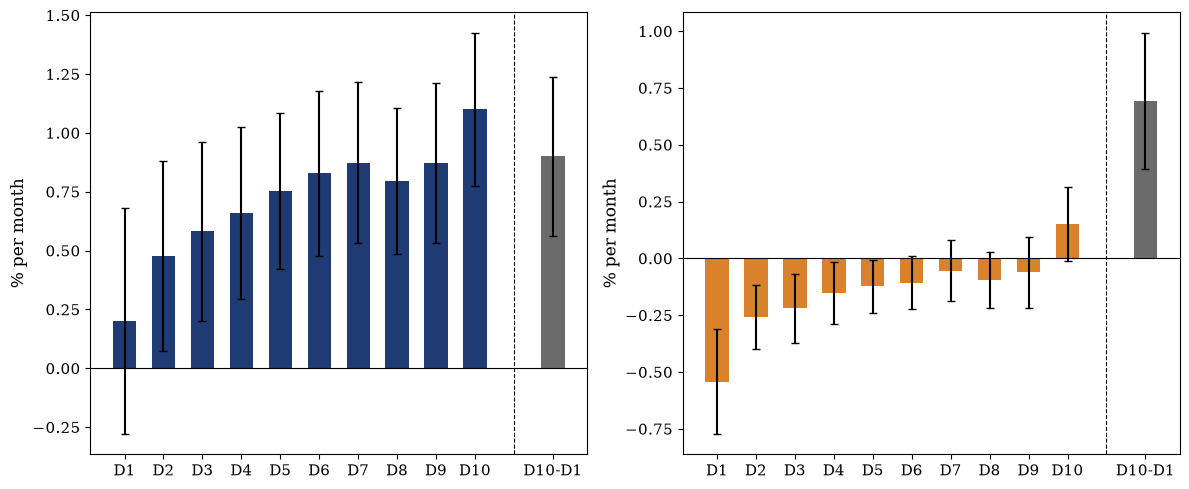

In [9]:
# Factor regressions (CAPM, FF3, FF5, FF5+Mom) by decile and Long-Short, HAC(6) standard
# errors; single regression function reused in Sections 3-5. Table 4: value-weighted decile
# sort. Table 5: Long-Short FF5+Mom factor exposures. Figure 1: mean excess return and
# FF5+Mom alpha by decile.
ff5mom = ff5.join(mom, how="inner")
ff3_r = ff3.add_suffix("_ff3")
pr_m = portfolio_returns.copy(); pr_m["month"] = pr_m.index.to_period("M")
ff5mom_m = ff5mom.copy(); ff5mom_m["month"] = ff5mom_m.index.to_period("M")
ff3_m = ff3_r.copy(); ff3_m["month"] = ff3_m.index.to_period("M")
common_data = (
    pr_m.set_index("month").join(ff5mom_m.set_index("month"), how="inner")
    .join(ff3_m.set_index("month"), how="inner").dropna().sort_index()
)
assert len(common_data) == 612, f"Expected 612 months, got {len(common_data)}"

model_specs = {
    "CAPM": (["Mkt-RF"], "RF"),
    "FF3": (["Mkt-RF_ff3", "SMB_ff3", "HML_ff3"], "RF_ff3"),
    "FF5": (["Mkt-RF", "SMB", "HML", "RMW", "CMA"], "RF"),
    "FF5+Mom": (["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"], "RF"),
}


def hac_reg(y, X):
    """Single HAC(6) regression function, reused for every factor model in the notebook."""
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": 6})


def mean_tstat(y):
    """HAC(6) mean/t-stat of a series (constant-only regression), reused everywhere a plain mean is needed."""
    X = np.ones((len(y), 1))
    m = sm.OLS(y.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


def fmt_coef(coef, t, p):
    return f"{coef:.4f}{stars(p)} ({t:.2f})"


decile_ports = [f"D{i}" for i in range(1, 11)]
fitted_models = {}
for port in decile_ports + ["LS_D10_D1"]:
    zero_cost = port.startswith("LS_")
    for model_name, (fc, rf_col) in model_specs.items():
        y = common_data[port] if zero_cost else common_data[port] - common_data[rf_col]
        fitted_models[(port, model_name)] = hac_reg(y, common_data[fc])

# Eligible-universe benchmark (VW, all stocks with a composite score): FF5+Mom alpha quoted in the text
univ_grouped = vw_data.groupby("target_month")
universe_returns = univ_grouped["weighted_ret"].sum() / univ_grouped["formation_mktcap"].sum()
univ_m = universe_returns.rename("UNIV").to_frame()
univ_m["month"] = univ_m.index.to_period("M")
univ_cd = univ_m.set_index("month").join(common_data[model_specs["FF5+Mom"][0] + ["RF"]], how="inner").dropna()
univ_fit = hac_reg(univ_cd["UNIV"] - univ_cd["RF"], univ_cd[model_specs["FF5+Mom"][0]])

table4_rows = {}
for port in decile_ports + ["LS_D10_D1"]:
    zero_cost = port.startswith("LS_")
    y_excess = common_data[port] if zero_cost else common_data[port] - common_data["RF"]
    mean_, t_, p_ = mean_tstat(y_excess)
    row = {"Mean excess return": fmt_coef(mean_, t_, p_)}
    for model_name in ["CAPM", "FF3", "FF5+Mom"]:
        m = fitted_models[(port, model_name)]
        row[f"Alpha {model_name}"] = fmt_coef(m.params["const"], m.tvalues["const"], m.pvalues["const"])
    table4_rows[port] = row
table4_rows["Eligible universe"] = {
    "Mean excess return": "", "Alpha CAPM": "", "Alpha FF3": "",
    "Alpha FF5+Mom": fmt_coef(univ_fit.params["const"], univ_fit.tvalues["const"], univ_fit.pvalues["const"]),
}
table4 = pd.DataFrame(table4_rows).T
print("TABLE 4 - Value-weighted decile portfolio sort (plus eligible-universe FF5+Mom alpha)")
display(table4)

# TABLE 5 - Long-Short FF5+Mom factor exposures
ls_ff5mom = fitted_models[("LS_D10_D1", "FF5+Mom")]
table5 = pd.DataFrame({
    f: {"Coefficient": fmt_coef(ls_ff5mom.params[f], ls_ff5mom.tvalues[f], ls_ff5mom.pvalues[f])}
    for f in ["const"] + model_specs["FF5+Mom"][0]
}).T.rename(index={"const": "Alpha"})
table5.loc["R2"] = f"{ls_ff5mom.rsquared:.3f}"
print("\nTABLE 5 - Long-Short (D10-D1) FF5+Mom factor exposures")
display(table5)

# FIGURE 1 - mean excess return and FF5+Mom alpha by decile, 95% HAC CI
mean_excess_vals, mean_excess_ci = [], []
for port in decile_ports:
    m_, t_, p_ = mean_tstat(common_data[port] - common_data["RF"])
    se_ = m_ / t_ if t_ != 0 else 0.0
    mean_excess_vals.append(m_ * 100); mean_excess_ci.append(1.96 * se_ * 100)
m_ls, t_ls, p_ls = mean_tstat(common_data["LS_D10_D1"])
se_ls = m_ls / t_ls if t_ls != 0 else 0.0
mean_excess_vals.append(m_ls * 100); mean_excess_ci.append(1.96 * se_ls * 100)

alpha_vals, alpha_ci = [], []
for port in decile_ports + ["LS_D10_D1"]:
    m = fitted_models[(port, "FF5+Mom")]
    alpha_vals.append(m.params["const"] * 100); alpha_ci.append(1.96 * m.bse["const"] * 100)

x_deciles, x_ls = np.arange(10), 11
x_all, labels = list(x_deciles) + [x_ls], decile_ports + ["D10-D1"]

with plt.rc_context({"font.family": "serif"}):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.patch.set_facecolor("white")
    ax = axes[0]
    ax.set_facecolor("white")
    ax.bar(x_deciles, mean_excess_vals[:10], yerr=mean_excess_ci[:10], color="#1f3b73", width=0.6, capsize=3)
    ax.bar([x_ls], [mean_excess_vals[10]], yerr=[mean_excess_ci[10]], color="#6b6b6b", width=0.6, capsize=3)
    ax.axvline(10, color="black", linewidth=0.8, linestyle="--")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x_all); ax.set_xticklabels(labels)
    ax.set_ylabel("% per month", fontsize=12)
    ax.tick_params(axis="both", labelsize=11)

    ax = axes[1]
    ax.set_facecolor("white")
    ax.bar(x_deciles, alpha_vals[:10], yerr=alpha_ci[:10], color="#d9822b", width=0.6, capsize=3)
    ax.bar([x_ls], [alpha_vals[10]], yerr=[alpha_ci[10]], color="#6b6b6b", width=0.6, capsize=3)
    ax.axvline(10, color="black", linewidth=0.8, linestyle="--")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x_all); ax.set_xticklabels(labels)
    ax.set_ylabel("% per month", fontsize=12)
    ax.tick_params(axis="both", labelsize=11)

    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    fig.savefig("figures/fig_deciles.pdf")
    plt.show()

In [10]:
# TABLE 6 - Fama-MacBeth cross-sectional regressions of next-month excess returns
rf_by_target = ff5["RF"].copy(); rf_by_target.index = rf_by_target.index.to_period("M")

fmb_signal_cols = ["composite_score", "asset_growth_neg", "gpa", "ep", "nsi_neg", "resid_mom"]
fmb_data = formation.dropna(subset=["realized_ret"]).merge(
    merged[["PERMNO", "MthCalDt"] + fmb_signal_cols],
    left_on=["PERMNO", "formation_month"], right_on=["PERMNO", "MthCalDt"], how="inner",
)
fmb_data["ln_mktcap"] = np.log(fmb_data["formation_mktcap"])
fmb_data["target_period"] = fmb_data["target_month"].dt.to_period("M")
fmb_data["rf"] = fmb_data["target_period"].map(rf_by_target)
fmb_data["excess_ret"] = fmb_data["realized_ret"] - fmb_data["rf"]


def add_std_col(df, col, group_col="formation_month"):
    def _transform(s):
        lo, hi = s.quantile([0.01, 0.99])
        w = s.clip(lo, hi)
        std = w.std()
        return (w - w.mean()) / std if std > 0 else w * 0
    return df.groupby(group_col)[col].transform(_transform)


for col in fmb_signal_cols + ["ln_mktcap"]:
    fmb_data[f"std_{col}"] = add_std_col(fmb_data, col)


def run_fama_macbeth(data, rhs_cols, month_col="formation_month"):
    coef_rows = []
    for month, g in data.groupby(month_col):
        if len(g) < len(rhs_cols) + 5:
            continue
        y = g["excess_ret"].values
        X = np.column_stack([np.ones(len(g))] + [g[c].values for c in rhs_cols])
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        fitted = X @ beta
        ss_res = np.sum((y - fitted) ** 2)
        ss_tot = np.sum((y - y.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
        coef_rows.append({"month": month, "n": len(g), "r2": r2, "const": beta[0], **dict(zip(rhs_cols, beta[1:]))})
    return pd.DataFrame(coef_rows).set_index("month")


def fm_summary(coef_df, rhs_cols):
    rows = []
    for col in ["const"] + rhs_cols:
        s = coef_df[col].dropna()
        mean_, t_, p_ = mean_tstat(s)
        rows.append({"variable": col, "mean coef. (%/month)": mean_ * 100, "t-stat (NW)": t_, "p-value": p_})
    return pd.DataFrame(rows).set_index("variable"), coef_df["r2"].mean(), coef_df["n"].mean()


spec1_cols = ["std_composite_score", "std_ln_mktcap"]
coef_spec1 = run_fama_macbeth(fmb_data, spec1_cols)
summary_spec1, r2_spec1, n_spec1 = fm_summary(coef_spec1, spec1_cols)

spec2_cols = ["std_asset_growth_neg", "std_gpa", "std_ep", "std_nsi_neg", "std_resid_mom", "std_ln_mktcap"]
coef_spec2 = run_fama_macbeth(fmb_data, spec2_cols)
summary_spec2, r2_spec2, n_spec2 = fm_summary(coef_spec2, spec2_cols)

row_labels = {
    "std_composite_score": "Composite score", "std_asset_growth_neg": "Asset growth (neg.)",
    "std_gpa": "Gross profitability", "std_ep": "Earnings-to-price", "std_nsi_neg": "Net share issuance (neg.)",
    "std_resid_mom": "Residual momentum", "std_ln_mktcap": "ln(ME)", "const": "Constant",
}
row_order = ["std_composite_score", "std_asset_growth_neg", "std_gpa", "std_ep", "std_nsi_neg", "std_resid_mom", "std_ln_mktcap", "const"]


def fmt_fm(summary, var):
    if var not in summary.index:
        return ""
    coef, t, p = summary.loc[var, ["mean coef. (%/month)", "t-stat (NW)", "p-value"]]
    return f"{coef:.3f}{stars(p)} ({t:.2f})"


fm_rows = [{"Variable": row_labels[v], "(1) Composite": fmt_fm(summary_spec1, v), "(2) Five signals": fmt_fm(summary_spec2, v)} for v in row_order]
fm_rows += [
    {"Variable": "Average R2", "(1) Composite": f"{r2_spec1:.3f}", "(2) Five signals": f"{r2_spec2:.3f}"},
    {"Variable": "Average stocks per month", "(1) Composite": f"{n_spec1:.0f}", "(2) Five signals": f"{n_spec2:.0f}"},
    {"Variable": "Months", "(1) Composite": f"{len(coef_spec1)}", "(2) Five signals": f"{len(coef_spec2)}"},
]
fm_table = pd.DataFrame(fm_rows).set_index("Variable")
print("TABLE 6 - Fama-MacBeth regressions of next-month excess returns")
print("Coefficients in %/month for a one-standard-deviation change (winsorized 1%/99%, standardized monthly); Newey-West (6 lags) t-stats.")
display(fm_table)

TABLE 6 - Fama-MacBeth regressions of next-month excess returns
Coefficients in %/month for a one-standard-deviation change (winsorized 1%/99%, standardized monthly); Newey-West (6 lags) t-stats.


,(1) Composite,(2) Five signals
Variable,,
Composite score,0.281*** (7.35),
Asset growth (neg.),,0.107*** (3.27)
Gross profitability,,0.081** (2.11)
Earnings-to-price,,0.145** (2.32)
Net share issuance (neg.),,0.072*** (3.14)
Residual momentum,,0.256*** (6.08)
ln(ME),-0.108 (-1.37),-0.132* (-1.89)
Constant,0.943*** (4.11),0.943*** (4.11)
Average R2,0.024,0.048


Final cumulative multiple, volatility-matched to the Long-Short (D10-D1):
  Long-Short D10-D1 (gross): x166.18
  HML: x3.95
  RMW: x13.38
  CMA: x6.81
  Mom: x9.29


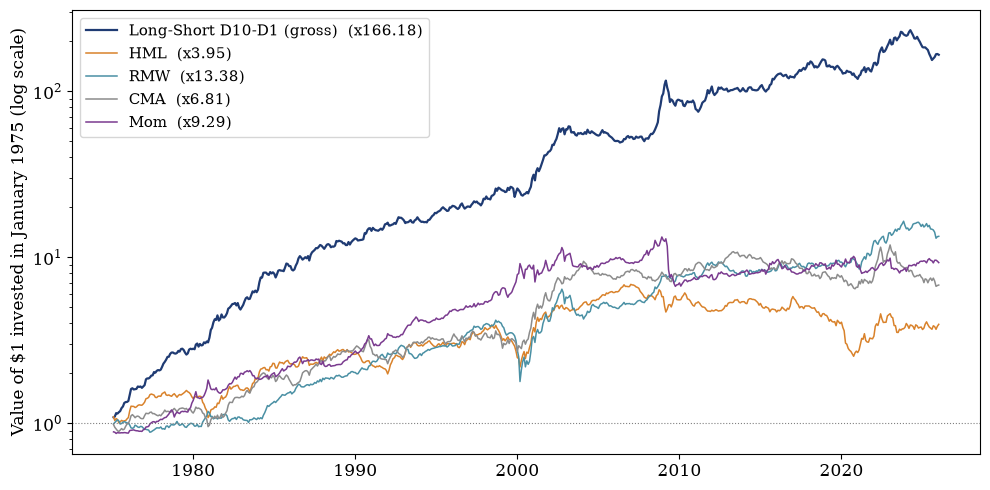

In [11]:
# FIGURE 2 - Long-Short (D10-D1) vs known factors, rescaled to equal volatility
factors_chart = {
    "Long-Short D10-D1 (gross)": common_data["LS_D10_D1"],
    "HML": common_data["HML"], "RMW": common_data["RMW"], "CMA": common_data["CMA"], "Mom": common_data["Mom"],
}
x_dates = common_data.index.to_timestamp(how="end")
colors_chart = {"Long-Short D10-D1 (gross)": "#1f3b73", "HML": "#d9822b", "RMW": "#4a90a4", "CMA": "#8c8c8c", "Mom": "#7a3b8f"}

vol_ls = common_data["LS_D10_D1"].std()
voladj_series, voladj_multiples = {}, {}
for label, s in factors_chart.items():
    scale = vol_ls / s.std() if s.std() > 0 else 1.0
    cum = (1 + s * scale).cumprod()
    voladj_series[label] = cum
    voladj_multiples[label] = cum.iloc[-1]

print("Final cumulative multiple, volatility-matched to the Long-Short (D10-D1):")
for label, mult in voladj_multiples.items():
    print(f"  {label}: x{mult:.2f}")

with plt.rc_context({"font.family": "serif"}):
    fig, ax = plt.subplots(figsize=(10, 5))
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    for label, cum in voladj_series.items():
        ax.plot(x_dates, cum.values, color=colors_chart[label], linewidth=1.6 if "Long-Short" in label else 1.1,
                label=f"{label}  (x{voladj_multiples[label]:.2f})")
    ax.axhline(1.0, color="grey", linewidth=0.8, linestyle=":")
    ax.set_yscale("log")
    ax.set_ylabel("Value of $1 invested in January 1975 (log scale)", fontsize=12)
    ax.tick_params(axis="both", labelsize=12)
    ax.legend(loc="upper left", fontsize=11)
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    fig.savefig("figures/fig_factors_voladj.pdf")
    plt.show()

## 4. Transaction Costs

Monthly turnover and a Gibbs half-spread plus square-root price-impact cost model, applied to the Long-Short's gross returns.

In [12]:
# Turnover per leg (D10, D1, Long-Short), no division by 2; Gibbs (2009) half-spread +
# square-root price-impact trading-cost model, 100 M$ per leg in December 2025 terms
tc_legs = {10: "D10", 1: "D1"}
CAPITAL_PER_LEG_DEC2025 = 100e6
TC_THETA = {"micro": 2.5, "small": 1.5, "large": 1.0}

tc_hold = vw_data.loc[
    vw_data["portfolio"].isin(tc_legs),
    ["PERMNO", "portfolio", "target_month", "target_month_num", "formation_mktcap", "realized_ret"],
].copy()
tc_hold["w"] = tc_hold["formation_mktcap"] / tc_hold.groupby(["target_month_num", "portfolio"])["formation_mktcap"].transform("sum")

tc_hold = tc_hold.merge(
    crsp[["PERMNO", "month_num", "MthCap", "MthRetx"]].rename(
        columns={"month_num": "target_month_num", "MthCap": "mcap_end", "MthRetx": "retx_end"}),
    on=["PERMNO", "target_month_num"], how="left",
)
tc_no_end_cap = tc_hold["mcap_end"].isna() | (tc_hold["mcap_end"] <= 0)
tc_hold.loc[tc_no_end_cap, "mcap_end"] = tc_hold["formation_mktcap"] * (1 + tc_hold["realized_ret"])


def tc_turnover(hold, growth):
    h = hold.assign(w_star=hold["w"] * growth)
    h["w_tilde"] = h["w_star"] / h.groupby(["target_month_num", "portfolio"])["w_star"].transform("sum")
    new = h[["PERMNO", "portfolio", "target_month_num", "w"]].rename(columns={"w": "w_new"})
    old = h[["PERMNO", "portfolio", "target_month_num", "w_tilde"]].assign(target_month_num=lambda d: d["target_month_num"] + 1)
    tr = new.merge(old, on=["PERMNO", "portfolio", "target_month_num"], how="outer")
    tr = tr[tr["target_month_num"].isin(new["target_month_num"].unique())].fillna({"w_new": 0.0, "w_tilde": 0.0})
    tr["dw"] = (tr["w_new"] - tr["w_tilde"]).abs()
    return tr


tc_trades = tc_turnover(tc_hold, tc_hold["mcap_end"] / tc_hold["formation_mktcap"])
tc_month_dates = tc_hold.groupby("target_month_num")["target_month"].first()
tc_trades["target_month"] = tc_trades["target_month_num"].map(tc_month_dates)

tc_turn = tc_trades.groupby(["target_month", "portfolio"])["dw"].sum().unstack("portfolio").rename(columns=tc_legs)[["D10", "D1"]]
tc_turn["LS"] = tc_turn["D10"] + tc_turn["D1"]
assert tc_turn.index.equals(portfolio_returns.index) and len(tc_turn) == 612, "Turnover months differ from the 612 official months"
assert tc_turn[["D10", "D1"]].le(2 + 1e-9).all().all() and tc_turn["LS"].le(4 + 1e-9).all(), "Turnover above its theoretical maximum"

# Half-spread: Gibbs estimate of year Y-1 for a trade in year Y; else expanding mean of earlier months, same size bucket
tc_univ = crsp[["PERMNO", "month_num", "MthCalDt", "MthCap", "MthPrcVol"]].copy()
tc_univ["MthPrcVol"] = pd.to_numeric(tc_univ["MthPrcVol"], errors="coerce")
tc_univ["bucket"] = pd.cut(tc_univ.groupby("month_num")["MthCap"].rank(pct=True), [0, 0.2, 0.5, 1.0],
                           labels=["micro", "small", "large"]).astype(str)

month_start = tc_univ["MthCalDt"].values.astype("datetime64[M]")
tc_univ["adv"] = tc_univ["MthPrcVol"] / np.busday_count(month_start, month_start + np.timedelta64(1, "M"))
tc_univ = tc_univ.sort_values(["PERMNO", "month_num"])
tc_univ["adv3"] = tc_univ.groupby("PERMNO")["adv"].transform(lambda s: s.rolling(3, min_periods=1).mean())
tc_univ["adv_filled"] = ~tc_univ["adv3"].gt(0)
tc_univ["adv3"] = tc_univ["adv3"].where(~tc_univ["adv_filled"]).fillna(tc_univ.groupby(["month_num", "bucket"])["adv3"].transform("median"))

gibbs = gibbs_raw.assign(year=lambda d: d["year"] + 1)
tc_univ["year"] = tc_univ["MthCalDt"].dt.year
tc_univ = tc_univ.merge(gibbs, on=["PERMNO", "year"], how="left")

all_months = pd.RangeIndex(tc_univ["month_num"].min(), tc_univ["month_num"].max() + 1)
bucket_obs = tc_univ.dropna(subset=["c"]).groupby(["month_num", "bucket"])["c"].agg(["sum", "count"]).unstack("bucket")
bucket_obs = bucket_obs.reindex(all_months).fillna(0)
expanding_hs = (bucket_obs["sum"].cumsum().shift(1) / bucket_obs["count"].cumsum().shift(1)).stack().rename("hs_fill")
tc_univ = tc_univ.merge(expanding_hs, left_on=["month_num", "bucket"], right_index=True, how="left")
tc_univ["half_spread"] = tc_univ["c"].fillna(tc_univ["hs_fill"])

nyse_cap = tc_univ.groupby("month_num")["MthCap"].sum() * 1000
tc_capital = CAPITAL_PER_LEG_DEC2025 * nyse_cap / nyse_cap.loc[2025 * 12 + 12]

tc_tr = tc_trades.loc[tc_trades["dw"] > 0].assign(trade_month_num=lambda d: d["target_month_num"] - 1)
tc_tr = pd.merge_asof(
    tc_tr.sort_values("trade_month_num"),
    tc_univ[["PERMNO", "month_num", "bucket", "adv3", "half_spread"]].sort_values("month_num"),
    left_on="trade_month_num", right_on="month_num", by="PERMNO", direction="backward",
)
assert tc_tr["half_spread"].notna().all() and tc_tr["adv3"].gt(0).all(), "Missing half-spread or ADV for a trade"

tc_tr["trade_usd"] = tc_tr["dw"] * tc_tr["trade_month_num"].map(tc_capital)
tc_tr["participation"] = tc_tr["trade_usd"] / tc_tr["adv3"]
tc_tr["impact"] = tc_tr["bucket"].map(TC_THETA) * np.sqrt(tc_tr["participation"]) / 100
tc_tr["cost_spread"] = tc_tr["dw"] * tc_tr["half_spread"]
tc_tr["cost_impact"] = tc_tr["dw"] * tc_tr["impact"]

tc_cost = tc_tr.groupby(["target_month", "portfolio"])[["cost_spread", "cost_impact"]].sum().unstack("portfolio")
tc_cost = tc_cost.reindex(portfolio_returns.index).fillna(0.0)
tc_cost_leg = pd.DataFrame({tc_legs[p]: tc_cost[("cost_spread", p)] + tc_cost[("cost_impact", p)] for p in tc_legs})
tc_cost_leg["LS"] = tc_cost_leg["D10"] + tc_cost_leg["D1"]

tc_turn_mean = tc_turn.iloc[1:].mean()
tc_cost_mean_bps = tc_cost_leg.iloc[1:].mean() * 1e4
print(f"Mean monthly turnover (excl. Jan-1975 build): D10 {tc_turn_mean['D10']:.1%}, D1 {tc_turn_mean['D1']:.1%}, Long-Short {tc_turn_mean['LS']:.1%}")
print(f"Mean monthly cost (bps): D10 {tc_cost_mean_bps['D10']:.1f}, D1 {tc_cost_mean_bps['D1']:.1f}, Long-Short {tc_cost_mean_bps['LS']:.1f}")
print(f"Participation: median {tc_tr['participation'].median():.3%}, P99 {tc_tr['participation'].quantile(0.99):.2%} of ADV")

Mean monthly turnover (excl. Jan-1975 build): D10 65.1%, D1 56.4%, Long-Short 121.5%
Mean monthly cost (bps): D10 26.5, D1 22.8, Long-Short 49.4
Participation: median 0.267%, P99 20.77% of ADV


TABLE 7 - Official strategy, gross vs net of trading costs (HAC t-stats; * p<0.10, ** p<0.05, *** p<0.01)


,CAGR,Ann. Vol.,Sharpe,Max DD,Alpha CAPM,Alpha FF3,Alpha FF5,Alpha FF5+Mom,CAPM beta,Turnover (%/m),Cost (bps/m)
Long-Short gross,10.55%,12.18%,0.886,-35.1%,0.0112*** (6.82),0.0107*** (6.64),0.0079*** (5.40),0.0069*** (4.52),-0.288,121.5%,49.4
Long-Short net,4.21%,12.11%,0.401,-41.8%,0.0062*** (3.89),0.0058*** (3.64),0.0030** (2.09),0.0021 (1.36),-0.288,121.5%,49.4
Mkt-RF (benchmark),8.10%,15.54%,0.581,-54.1%,-,-,-,-,1.000,-,-


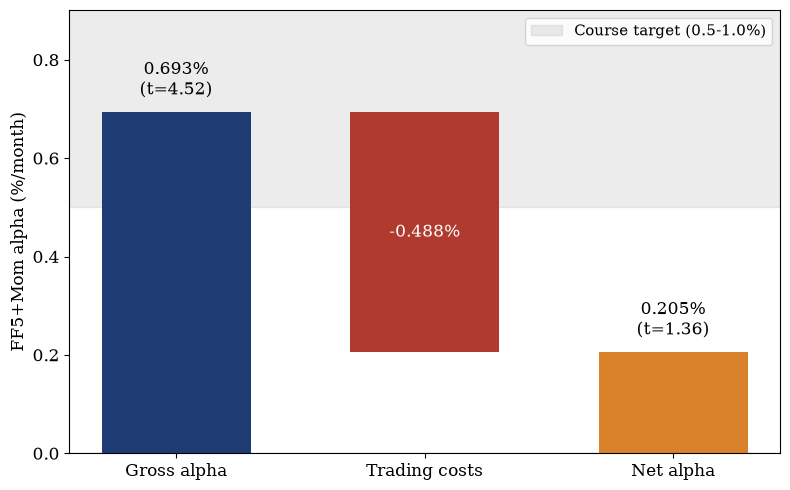

Final cumulative multiple, Long-Short D10-D1:
  gross: x166.18
  net: x8.18


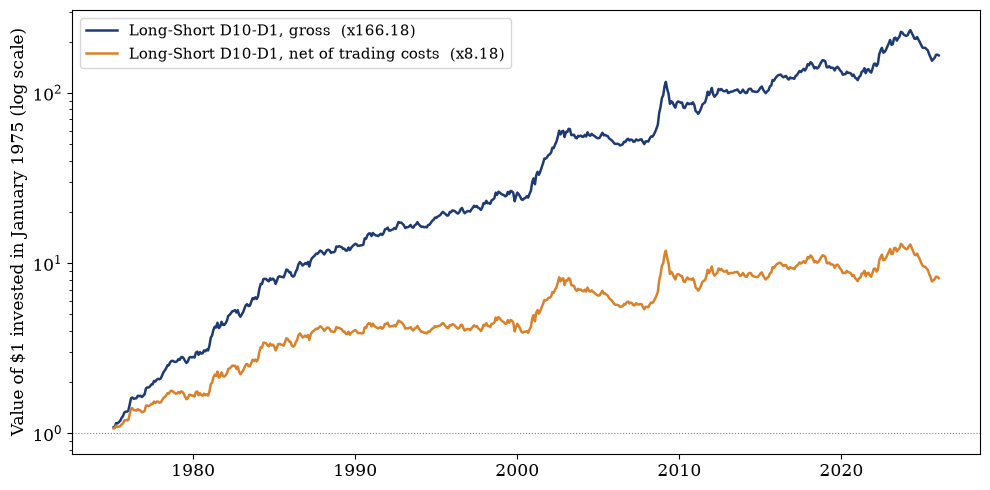

In [13]:
# Net-of-cost returns: TABLE 7 (gross vs net performance), FIGURE 3 (cost bridge),
# FIGURE 4 (cumulative performance, gross vs net)
tc_returns = pd.DataFrame({
    "LS_gross": portfolio_returns["LS_D10_D1"], "LS_net": portfolio_returns["LS_D10_D1"] - tc_cost_leg["LS"],
})
tc_returns.index = tc_returns.index.to_period("M")
tc_common = common_data[sorted({c for f, rf in model_specs.values() for c in f + [rf]})].join(tc_returns, how="inner")
assert len(tc_common) == 612, "Expected 612 months in the net-return sample"

net_models = {m: hac_reg(tc_common["LS_net"], tc_common[fc]) for m, (fc, rf_col) in model_specs.items()}

rf_monthly = ff5["RF"].copy()
rf_monthly.index = rf_monthly.index.to_period("M")


def perf_stats(returns, label, excess_rf):
    """Single performance-statistics function, reused for every table in Sections 4-5."""
    s = returns.dropna()
    months = s.index if isinstance(s.index, pd.PeriodIndex) else s.index.to_period("M")
    rf = rf_monthly.reindex(months).values if excess_rf else 0.0
    excess = s - rf
    n = len(s)
    cum = (1 + s).cumprod()
    return {
        "portfolio": label, "mean_monthly": s.mean(), "cagr": cum.iloc[-1] ** (12 / n) - 1,
        "ann_vol": s.std() * np.sqrt(12),
        "sharpe": excess.mean() / excess.std() * np.sqrt(12) if excess.std() > 0 else np.nan,
        "max_drawdown": (cum / cum.cummax() - 1).min(), "cum_multiple": cum.iloc[-1],
    }


tc_perf = pd.DataFrame([
    perf_stats(tc_common["LS_gross"], "LS_gross", excess_rf=False),
    perf_stats(tc_common["LS_net"], "LS_net", excess_rf=False),
    perf_stats(tc_common["Mkt-RF"], "Mkt-RF", excess_rf=False),
]).set_index("portfolio")


def ls_alpha(col, model):
    m = fitted_models[("LS_D10_D1", model)] if col == "LS_gross" else net_models[model]
    return fmt_coef(m.params["const"], m.tvalues["const"], m.pvalues["const"])


def ls_beta(col):
    if col == "LS_gross":
        return f"{fitted_models[('LS_D10_D1', 'CAPM')].params['Mkt-RF']:+.3f}"
    if col == "LS_net":
        return f"{net_models['CAPM'].params['Mkt-RF']:+.3f}"
    return "1.000"


table7 = pd.DataFrame({
    label: {
        "CAGR": f"{tc_perf.loc[col, 'cagr']:.2%}",
        "Ann. Vol.": f"{tc_perf.loc[col, 'ann_vol']:.2%}",
        "Sharpe": f"{tc_perf.loc[col, 'sharpe']:.3f}",
        "Max DD": f"{tc_perf.loc[col, 'max_drawdown']:.1%}",
        "Alpha CAPM": ls_alpha(col, "CAPM") if col != "Mkt-RF" else "-",
        "Alpha FF3": ls_alpha(col, "FF3") if col != "Mkt-RF" else "-",
        "Alpha FF5": ls_alpha(col, "FF5") if col != "Mkt-RF" else "-",
        "Alpha FF5+Mom": ls_alpha(col, "FF5+Mom") if col != "Mkt-RF" else "-",
        "CAPM beta": ls_beta(col),
        "Turnover (%/m)": f"{tc_turn_mean['LS']:.1%}" if col != "Mkt-RF" else "-",
        "Cost (bps/m)": f"{tc_cost_mean_bps['LS']:.1f}" if col != "Mkt-RF" else "-",
    }
    for label, col in [("Long-Short gross", "LS_gross"), ("Long-Short net", "LS_net"), ("Mkt-RF (benchmark)", "Mkt-RF")]
}).T
print("TABLE 7 - Official strategy, gross vs net of trading costs (HAC t-stats; * p<0.10, ** p<0.05, *** p<0.01)")
display(table7)

# FIGURE 3 - gross -> trading costs -> net alpha bridge (FF5+Mom, Long-Short)
br_gross = fitted_models[("LS_D10_D1", "FF5+Mom")]
br_net = net_models["FF5+Mom"]
br_gross_alpha, br_gross_t = br_gross.params["const"] * 100, br_gross.tvalues["const"]
br_net_alpha, br_net_t = br_net.params["const"] * 100, br_net.tvalues["const"]
br_cost = br_gross_alpha - br_net_alpha

with plt.rc_context({"font.family": "serif"}):
    fig_bridge, ax = plt.subplots(figsize=(8, 5))
    fig_bridge.patch.set_facecolor("white")
    ax.set_facecolor("white")
    ax.axhspan(0.5, 1.0, color="grey", alpha=0.15, label="Course target (0.5-1.0%)", zorder=0)
    ax.bar(0, br_gross_alpha, width=0.6, color="#1f3b73", zorder=2)
    ax.bar(1, br_cost, bottom=br_net_alpha, width=0.6, color="#b03a2e", zorder=2)
    ax.bar(2, br_net_alpha, width=0.6, color="#d9822b", zorder=2)
    ax.axhline(0, color="black", linewidth=0.8, zorder=1)
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["Gross alpha", "Trading costs", "Net alpha"], fontsize=12)
    ax.set_ylabel("FF5+Mom alpha (%/month)", fontsize=12)
    ax.tick_params(axis="y", labelsize=12)
    ax.text(0, br_gross_alpha + 0.025, f"{br_gross_alpha:.3f}%\n(t={br_gross_t:.2f})", ha="center", va="bottom", fontsize=12)
    ax.text(1, br_net_alpha + br_cost / 2, f"-{br_cost:.3f}%", ha="center", va="center", fontsize=12, color="white")
    ax.text(2, br_net_alpha + 0.025, f"{br_net_alpha:.3f}%\n(t={br_net_t:.2f})", ha="center", va="bottom", fontsize=12)
    ax.legend(loc="upper right", fontsize=11)
    ax.set_ylim(0, br_gross_alpha * 1.3)
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    fig_bridge.savefig("figures/fig_bridge.pdf")
    plt.show()

# FIGURE 4 - cumulative performance, gross vs net
fs_cum = (1 + tc_common[["LS_gross", "LS_net"]]).cumprod()
fs_cum.index = fs_cum.index.to_timestamp(how="end")
FS_COLORS = {"gross": "#1f3b73", "net": "#d9822b"}
print("Final cumulative multiple, Long-Short D10-D1:")
for col, key in [("LS_gross", "gross"), ("LS_net", "net")]:
    print(f"  {key}: x{fs_cum[col].iloc[-1]:.2f}")

with plt.rc_context({"font.family": "serif"}):
    fig_gn, ax = plt.subplots(figsize=(10, 5))
    fig_gn.patch.set_facecolor("white")
    ax.set_facecolor("white")
    for col, key, label in [("LS_gross", "gross", "Long-Short D10-D1, gross"), ("LS_net", "net", "Long-Short D10-D1, net of trading costs")]:
        ax.plot(fs_cum.index, fs_cum[col], color=FS_COLORS[key], linewidth=1.8, label=f"{label}  (x{fs_cum[col].iloc[-1]:.2f})")
    ax.axhline(1.0, color="grey", linewidth=0.8, linestyle=":")
    ax.set_yscale("log")
    ax.set_ylabel("Value of $1 invested in January 1975 (log scale)", fontsize=12)
    ax.tick_params(axis="both", labelsize=12)
    ax.legend(loc="upper left", fontsize=11)
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    fig_gn.savefig("figures/fig_gross_net.pdf")
    plt.show()

## 5. Robustness

Robustness of the official strategy by size and by sub-period, gross and net of trading costs.

In [14]:
# TABLE 8 - Robustness by size: deciles reformed within Small / Big / ex-microcap sub-universes
DECILE_LEVELS_RB = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


def form_deciles_generic(universe_df, score_col="composite_score"):
    bp = universe_df.groupby("MthCalDt")[score_col].quantile(DECILE_LEVELS_RB).unstack()
    bp.columns = [f"bp_{int(round(q * 100))}" for q in DECILE_LEVELS_RB]
    tmp = universe_df.merge(bp, left_on="MthCalDt", right_index=True, how="left")
    q = np.ones(len(tmp), dtype=float)
    for c in bp.columns:
        q += (tmp[score_col] > tmp[c]).astype(float)
    tmp["q_local"] = np.where(tmp[score_col].notna(), q, np.nan)

    f = tmp.loc[tmp["q_local"].notna(), ["PERMNO", "MthCalDt", "month_num", "q_local", "MthCap"]].copy()
    f = f.rename(columns={"MthCalDt": "formation_month", "q_local": "portfolio", "MthCap": "formation_mktcap"})
    f["target_month_num"] = f["month_num"] + 1
    f = f.merge(
        crsp_all_returns.rename(columns={"month_num": "target_month_num", "MthCalDt": "target_month", "MthRet": "realized_ret"}),
        on=["PERMNO", "target_month_num"], how="left",
    )
    f = f[f["target_month_num"].between(period_start_num, period_end_num)].copy()

    vw = f.dropna(subset=["portfolio", "realized_ret", "formation_mktcap"])
    vw = vw[vw["formation_mktcap"] > 0].copy()
    vw["weighted_ret"] = vw["realized_ret"] * vw["formation_mktcap"]
    grouped = vw.groupby(["target_month", "portfolio"])
    pr = (grouped["weighted_ret"].sum() / grouped["formation_mktcap"].sum()).unstack("portfolio")
    pr.columns = [f"D{int(c)}" for c in pr.columns]
    pr["LS_D10_D1"] = pr["D10"] - pr["D1"]
    return pr


eligible = merged.loc[merged["composite_score"].notna(), ["PERMNO", "MthCalDt", "month_num", "composite_score", "MthCap"]].copy()
cap_bp = eligible.groupby("MthCalDt")["MthCap"].quantile([0.2, 0.5]).unstack()
cap_bp.columns = ["cap_p20", "cap_p50"]
eligible = eligible.merge(cap_bp, left_on="MthCalDt", right_index=True, how="left")

pr_small = form_deciles_generic(eligible[eligible["MthCap"] <= eligible["cap_p50"]])
pr_big = form_deciles_generic(eligible[eligible["MthCap"] > eligible["cap_p50"]])
pr_exmicro = form_deciles_generic(eligible[eligible["MthCap"] > eligible["cap_p20"]])


def size_robustness_row(label, pr):
    ls = pr["LS_D10_D1"].dropna()
    pr_m = pr.copy(); pr_m["month"] = pr_m.index.to_period("M")
    cd = pr_m.set_index("month").join(common_data[["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom", "RF"]], how="inner").dropna()
    row = {"version": label, "LS mean return (%/month)": ls.mean() * 100, "LS Sharpe": ls.mean() / ls.std() * np.sqrt(12)}
    for model_name in ["CAPM", "FF5+Mom"]:
        fc, _ = model_specs[model_name]
        m = hac_reg(cd["LS_D10_D1"], cd[fc])
        row[f"Alpha {model_name}"] = fmt_coef(m.params["const"], m.tvalues["const"], m.pvalues["const"])
    return row


size_table = pd.DataFrame([
    size_robustness_row("Official (full universe)", portfolio_returns),
    size_robustness_row("Small (<= NYSE median)", pr_small),
    size_robustness_row("Big (> NYSE median)", pr_big),
    size_robustness_row("Ex-microcaps (> NYSE P20)", pr_exmicro),
]).set_index("version")
print("TABLE 8 - Robustness by size (gross returns only)")
display(size_table.round(4))

TABLE 8 - Robustness by size (gross returns only)


,LS mean return (%/month),LS Sharpe,Alpha CAPM,Alpha FF5+Mom
version,,,,
Official (full universe),0.8998,0.8863,0.0112*** (6.82),0.0069*** (4.52)
Small (<= NYSE median),0.9774,0.9525,0.0113*** (7.25),0.0081*** (5.02)
Big (> NYSE median),0.7197,0.7115,0.0094*** (5.95),0.0054*** (3.63)
Ex-microcaps (> NYSE P20),0.8204,0.8076,0.0104*** (6.56),0.0063*** (4.20)


TABLE 9 - Long-Short D10-D1 by sub-period, gross vs net of trading costs
Alphas: % per month, HAC(6) t-stat in brackets; * p<0.10, ** p<0.05, *** p<0.01


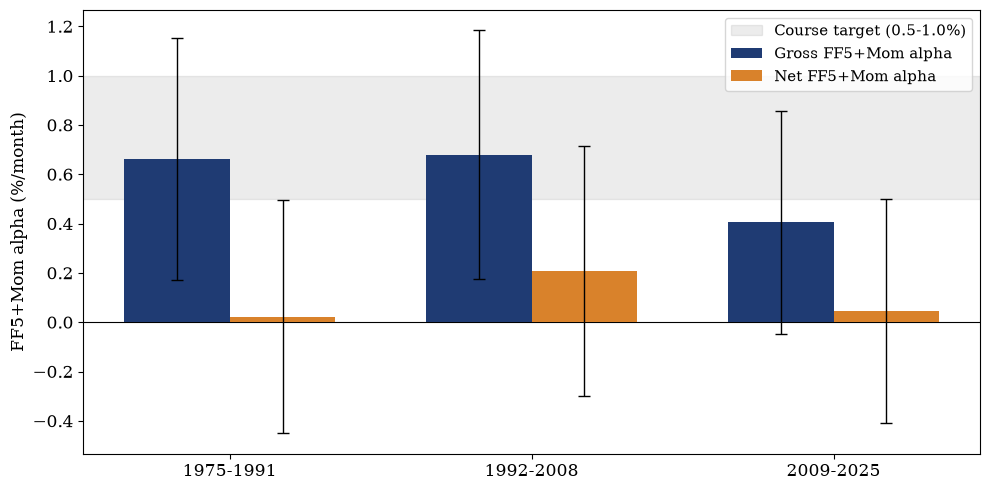

In [15]:
# TABLE 9 - Long-Short by sub-period (three 204-month periods), gross vs net; FIGURE 5
rb_periods = {"1975-1991": ("1975-01", "1991-12"), "1992-2008": ("1992-01", "2008-12"), "2009-2025": ("2009-01", "2025-12")}

rb_sub_rows, rb_sub_alpha = [], []
for period, (start, end) in rb_periods.items():
    d = tc_common.loc[start:end]
    for kind in ["gross", "net"]:
        perf = perf_stats(d[f"LS_{kind}"], period, excess_rf=False)
        row = {"Period": period, "Returns": kind, "N": len(d), "CAGR": perf["cagr"], "Sharpe": perf["sharpe"], "Max DD": perf["max_drawdown"]}
        for model_name, (fc, _) in model_specs.items():
            fit = hac_reg(d[f"LS_{kind}"], d[fc])
            a, t, p = fit.params["const"], fit.tvalues["const"], fit.pvalues["const"]
            row[model_name] = f"{a * 100:.3f}{stars(p)} ({t:.2f})"
            rb_sub_alpha.append({"Period": period, "Returns": kind, "Model": model_name, "alpha": a, "se": fit.bse["const"]})
        rb_sub_rows.append(row)

rb_sub = pd.DataFrame(rb_sub_rows).set_index(["Period", "Returns"])
rb_sub_alpha = pd.DataFrame(rb_sub_alpha)
assert rb_sub.xs("gross", level="Returns")["N"].sum() == 612, "Sub-periods do not cover the 612 months exactly"

print("TABLE 9 - Long-Short D10-D1 by sub-period, gross vs net of trading costs")
print("Alphas: % per month, HAC(6) t-stat in brackets; * p<0.10, ** p<0.05, *** p<0.01")
display(rb_sub.style.format({"CAGR": "{:.2%}", "Sharpe": "{:.3f}", "Max DD": "{:.1%}"}))

sp_periods = list(rb_periods)
sp_x = np.arange(len(sp_periods))
sp_width = 0.35

with plt.rc_context({"font.family": "serif"}):
    fig_sp, ax = plt.subplots(figsize=(10, 5))
    fig_sp.patch.set_facecolor("white")
    ax.set_facecolor("white")
    ax.axhspan(0.5, 1.0, color="grey", alpha=0.15, label="Course target (0.5-1.0%)", zorder=0)
    for kind, color, offset in [("gross", "#1f3b73", -sp_width / 2), ("net", "#d9822b", sp_width / 2)]:
        sub = rb_sub_alpha.query("Model == 'FF5+Mom' and Returns == @kind").set_index("Period").loc[sp_periods]
        ax.bar(sp_x + offset, sub["alpha"] * 100, sp_width, yerr=1.96 * sub["se"] * 100, capsize=4, color=color,
               label=f"{kind.capitalize()} FF5+Mom alpha", error_kw={"ecolor": "black", "elinewidth": 1}, zorder=2)
    ax.axhline(0, color="black", linewidth=0.8, zorder=1)
    ax.set_xticks(sp_x); ax.set_xticklabels(sp_periods, fontsize=12)
    ax.set_ylabel("FF5+Mom alpha (%/month)", fontsize=12)
    ax.tick_params(axis="y", labelsize=12)
    ax.legend(loc="upper right", fontsize=11)
    plt.tight_layout()
    os.makedirs("figures", exist_ok=True)
    fig_sp.savefig("figures/fig_subperiods.pdf")
    plt.show()